<a href="https://colab.research.google.com/github/Hyunwoo-Lim-dev/ai-sketch-classifier/blob/main/AI_Sketch_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Sketch Classifier - AI 그림 맞히기 프로젝트

## 1. 프로젝트 개요

본 프로젝트는 Google의 Quick, Draw! 데이터셋과 Keras를 활용하여 사용자가 그린 그림을 자동으로 분류하는 인공지능 모델을 구현하는 것을 목표로 한다.

AI 모델이 사과, 자전거, 고양이, 집, 별 총 5가지 종류의 그림을 학습하고, 사용자가 새로운 그림을 입력하면 해당 그림이 어떤 종류인지 예측하도록 구현하였다.

## 2. 개발 목적

이미지 분류 기술과 CNN(합성곱 신경망)의 작동 원리를 이해하고, 데이터 수집 및 전처리부터 모델 학습, 성능 평가, 새로운 이미지 추론까지 딥러닝 개발 과정을 직접 경험하고자 한다.

## 3. 개발 환경

- 개발 언어: Python
- 개발 환경: Google Colab
- 딥러닝 프레임워크: TensorFlow
- 고수준 API: Keras
- 데이터셋: Quick, Draw!
- 모델: CNN(합성곱 신경망)

## 4. 분류 대상

1. Apple (사과)
2. Bicycle (자전거)
3. Cat (고양이)
4. House (집)
5. Star (별)

TensorFlow 버전: 2.21.0
apple 데이터 다운로드 중...
apple: 4000개 로드 완료
bicycle 데이터 다운로드 중...
bicycle: 4000개 로드 완료
cat 데이터 다운로드 중...
cat: 4000개 로드 완료
house 데이터 다운로드 중...
house: 4000개 로드 완료
star 데이터 다운로드 중...
star: 4000개 로드 완료

전체 데이터 형태: (20000, 28, 28, 1)
전체 라벨 형태: (20000,)

학습 데이터: (16000, 28, 28, 1)
테스트 데이터: (4000, 28, 28, 1)


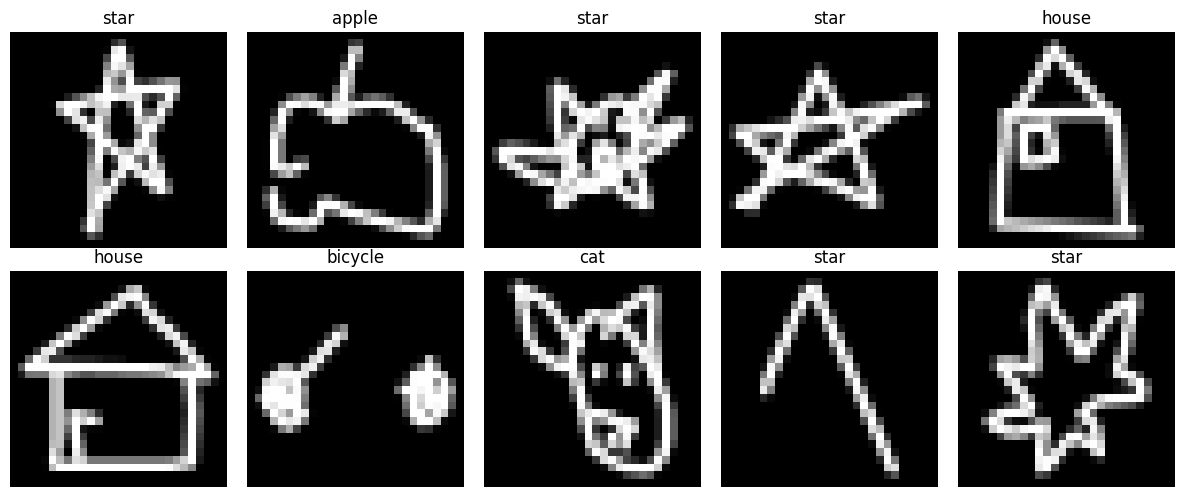

In [1]:

# ============================================
# 1. 라이브러리 불러오기
# ============================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import os

from sklearn.model_selection import train_test_split

print("TensorFlow 버전:", tf.__version__)


# ============================================
# 2. 데이터셋 다운로드
# ============================================

# 분류할 그림 종류
categories = ['apple', 'bicycle', 'cat', 'house', 'star']

# 클래스별 데이터 개수
SAMPLES_PER_CLASS = 4000

# 데이터 저장 폴더
os.makedirs('/content/quickdraw', exist_ok=True)

X_list = []
y_list = []

for label, category in enumerate(categories):

    print(f"{category} 데이터 다운로드 중...")

    url = (
        "https://storage.googleapis.com/"
        "quickdraw_dataset/full/numpy_bitmap/"
        + category + ".npy"
    )

    file_path = f"/content/quickdraw/{category}.npy"

    if not os.path.exists(file_path):
        urllib.request.urlretrieve(url, file_path)

    # Numpy 데이터 로드
    data = np.load(file_path)

    # 클래스별 데이터 일부만 사용
    data = data[:SAMPLES_PER_CLASS]

    X_list.append(data)
    y_list.append(
        np.full(len(data), label)
    )

    print(f"{category}: {len(data)}개 로드 완료")


# ============================================
# 3. 데이터 통합 및 전처리
# ============================================

X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# 이미지 형태를 (개수, 28, 28, 1)로 변경
X = X.reshape(-1, 28, 28, 1)

# 픽셀 값 정규화 (0~255 -> 0~1)
X = X.astype('float32') / 255.0

print("\n전체 데이터 형태:", X.shape)
print("전체 라벨 형태:", y.shape)


# ============================================
# 4. 학습 데이터와 테스트 데이터 분리
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)


# ============================================
# 5. 데이터 샘플 시각화
# ============================================

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_train[i].squeeze(),
        cmap='gray'
    )

    plt.title(categories[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 224,389 (876.52 KB)

 Trainable params: 224,389 (876.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.8145 - loss: 0.5406 - val_accuracy: 0.9203 - val_loss: 0.2440
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9273 - loss: 0.2256 - val_accuracy: 0.9434 - val_loss: 0.1758
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9447 - loss: 0.1721 - val_accuracy: 0.9516 - val_loss: 0.1560
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9532 - loss: 0.1435 - val_accuracy: 0.9519 - val_loss: 0.1475
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9613 - loss: 0.1243 - val_accuracy: 0.9575 - val_loss: 0.1369
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9655 - loss: 0.1086 - val_accuracy: 0.9569 - val_loss: 0.1319
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9688 - loss: 0.0954 - val_accuracy: 0.9563 - val_loss: 0.1325
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9720 - loss: 0.0879 - val_accuracy: 0

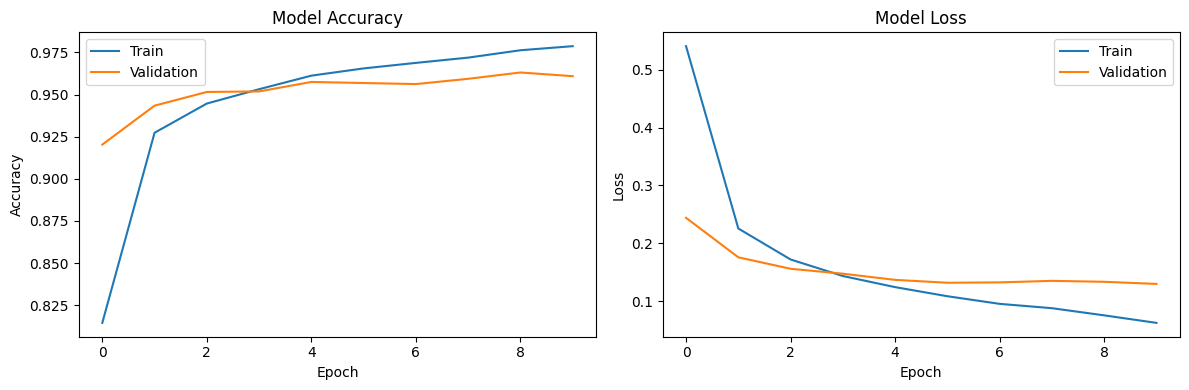

In [2]:

# ============================================
# 1. CNN 모델 구축
# ============================================

from tensorflow.keras import layers, models

model = models.Sequential([

    # 입력층
    layers.Input(shape=(28, 28, 1)),

    # 첫 번째 합성곱층
    layers.Conv2D(
        32,
        (3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D((2, 2)),

    # 두 번째 합성곱층
    layers.Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D((2, 2)),

    # 1차원으로 변환
    layers.Flatten(),

    # 완전 연결층
    layers.Dense(128, activation='relu'),

    # 과적합 방지
    layers.Dropout(0.3),

    # 출력층: 5개 클래스
    layers.Dense(
        len(categories),
        activation='softmax'
    )
])


# ============================================
# 2. 모델 컴파일
# ============================================

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


# ============================================
# 3. 모델 학습
# ============================================

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)


# ============================================
# 4. 모델 평가
# ============================================

test_loss, test_acc = model.evaluate(
    X_test,
    y_test,
    verbose=2
)

print(f"\n테스트 정확도: {test_acc * 100:.2f}%")


# ============================================
# 5. 학습 결과 그래프
# ============================================

plt.figure(figsize=(12, 4))

# 정확도
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


# 손실
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [3]:

# ============================================
# 1. 이미지 전처리 및 예측 함수
# ============================================

import base64
import re

from PIL import Image
from io import BytesIO

from google.colab import output
from IPython.display import display, HTML


def predict_drawing(data_url):

    # Base64 이미지 데이터 추출
    image_data = re.sub(
        '^data:image/.+;base64,',
        '',
        data_url
    )

    image_bytes = base64.b64decode(image_data)

    # 이미지 열기
    img = Image.open(
        BytesIO(image_bytes)
    ).convert('L')

    # NumPy 배열로 변환
    img_array = np.array(img)

    # 그림이 있는 영역 찾기
    coords = np.where(img_array > 20)

    if len(coords[0]) == 0:
        return "그림을 먼저 그려주세요."

    # 그림 영역 추출
    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()

    img = img.crop((
        x_min,
        y_min,
        x_max + 1,
        y_max + 1
    ))

    # 가로세로 비율을 유지하면서 20x20으로 축소
    img.thumbnail(
        (20, 20),
        Image.Resampling.LANCZOS
    )

    # 28x28 검정색 배경 생성
    new_img = Image.new(
        'L',
        (28, 28),
        0
    )

    # 그림을 중앙에 배치
    x_offset = (28 - img.width) // 2
    y_offset = (28 - img.height) // 2

    new_img.paste(
        img,
        (x_offset, y_offset)
    )

    # 정규화
    input_data = np.array(
        new_img,
        dtype=np.float32
    ) / 255.0

    # 모델 입력 형태 변경
    input_data = input_data.reshape(
        1, 28, 28, 1
    )

    # AI 예측
    predictions = model.predict(
        input_data,
        verbose=0
    )[0]

    # 가장 높은 확률의 클래스
    predicted_index = np.argmax(predictions)

    predicted_class = categories[predicted_index]

    confidence = predictions[predicted_index] * 100

    # 상위 3개 예측 결과
    top3 = np.argsort(predictions)[-3:][::-1]

    result = f"AI의 예측: {predicted_class.upper()} ({confidence:.2f}%)"

    for index in top3:
        result += (
            f" | {categories[index]}: "
            f"{predictions[index] * 100:.2f}%"
        )

    return result


# ============================================
# 2. Python 함수 등록
# ============================================

output.register_callback(
    'notebook.predict_drawing',
    predict_drawing
)


# ============================================
# 3. HTML5 Canvas 그림판
# ============================================

html_code = """

<div style="
    max-width:600px;
    margin:auto;
    text-align:center;
    font-family:Arial,sans-serif;
">

    <h2>🎨 AI 그림 맞히기 게임</h2>

    <p>
        사과, 자전거, 고양이, 집, 별 중 하나를 그려보세요!
    </p>

    <p style="color:#777;font-size:14px;">
        마우스로 그림을 그린 후 AI에게 맞혀보세요.
    </p>

    <!-- 그림판 -->
    <canvas id="drawCanvas"
        width="280"
        height="280"
        style="
            border:3px solid #555;
            background:black;
            cursor:crosshair;
            touch-action:none;
            border-radius:8px;
        ">
    </canvas>

    <br><br>

    <!-- 버튼 -->
    <button onclick="predictDrawing()"
        style="
            padding:12px 25px;
            font-size:16px;
            background:#1976D2;
            color:white;
            border:none;
            border-radius:8px;
            cursor:pointer;
        ">
        🤖 AI에게 물어보기
    </button>

    <button onclick="clearCanvas()"
        style="
            padding:12px 25px;
            font-size:16px;
            background:#757575;
            color:white;
            border:none;
            border-radius:8px;
            cursor:pointer;
        ">
        지우기
    </button>

    <!-- 결과 -->
    <div id="result"
        style="
            margin-top:20px;
            padding:20px;
            background:#f1f3f5;
            color:#222;
            border-radius:10px;
            font-size:17px;
            line-height:1.8;
            white-space:pre-line;
        ">
        그림을 그린 후 AI에게 물어보세요!
    </div>

</div>


<script>

// ========================================
// 1. Canvas 설정
// ========================================

const canvas = document.getElementById('drawCanvas');

const ctx = canvas.getContext('2d');

// 검정색 배경
ctx.fillStyle = 'black';

ctx.fillRect(
    0, 0,
    canvas.width,
    canvas.height
);

// 흰색 붓
ctx.strokeStyle = 'white';

ctx.lineWidth = 18;

ctx.lineCap = 'round';

ctx.lineJoin = 'round';

let drawing = false;


// ========================================
// 2. 마우스 좌표 계산
// ========================================

function getPosition(e) {

    const rect = canvas.getBoundingClientRect();

    return {
        x: (e.clientX - rect.left)
            * canvas.width / rect.width,

        y: (e.clientY - rect.top)
            * canvas.height / rect.height
    };
}


// ========================================
// 3. 그림 그리기
// ========================================

// 마우스 클릭
canvas.addEventListener('pointerdown', function(e) {

    drawing = true;

    canvas.setPointerCapture(e.pointerId);

    const pos = getPosition(e);

    ctx.beginPath();

    ctx.moveTo(pos.x, pos.y);

    ctx.lineTo(pos.x, pos.y);

    ctx.stroke();

});


// 마우스 이동
canvas.addEventListener('pointermove', function(e) {

    if (!drawing) return;

    const pos = getPosition(e);

    ctx.lineTo(pos.x, pos.y);

    ctx.stroke();

});


// 마우스 버튼 해제
canvas.addEventListener('pointerup', function() {

    drawing = false;

});

canvas.addEventListener('pointercancel', function() {

    drawing = false;

});


// ========================================
// 4. 그림판 초기화
// ========================================

function clearCanvas() {

    ctx.fillStyle = 'black';

    ctx.fillRect(
        0, 0,
        canvas.width,
        canvas.height
    );

    document.getElementById('result').innerText =
        '그림을 그린 후 AI에게 물어보세요!';

}


// ========================================
// 5. AI 추론 요청
// ========================================

async function predictDrawing() {

    const resultDiv = document.getElementById('result');

    resultDiv.innerText = '🤖 AI가 그림을 분석하고 있습니다...';

    // Canvas 이미지를 Base64로 변환
    const imageData = canvas.toDataURL('image/png');

    try {

        // Python 함수 호출
        const response = await google.colab.kernel.invokeFunction(
            'notebook.predict_drawing',
            [imageData],
            {}
        );

        // Python 결과 가져오기
        const result = response.data['text/plain'];

        // 결과 표시
        resultDiv.innerText = String(result).replace(/^['"]|['"]$/g, '');

    }

    catch(error) {

        resultDiv.innerText =
            '오류가 발생했습니다: ' + error.message;

    }

}

</script>

"""

display(HTML(html_code))


# 5. 프로젝트 결과 및 결론

## 1. 프로젝트 결과

Quick, Draw! 데이터셋을 활용하여 총 5가지 종류의 그림을 분류하는 CNN 기반 인공지능 모델을 구현하였다.

각 종류별 4,000장의 이미지 데이터를 활용하여 모델을 학습시켰으며, 테스트 데이터를 통해 분류 성능을 평가하였다.

- 테스트 정확도: (실제 실행 결과 입력)
- 학습 횟수: 10 Epoch
- 분류 대상: 5가지

## 2. 추론 결과

직접 그림판에 그림을 그린 후 AI 모델에 입력하여 예측 결과를 확인하였다.

AI가 예측한 그림 종류와 예측 확률을 확인할 수 있었으며, 실제 그림과 예측 결과를 비교할 수 있었다.

## 3. 프로젝트를 통해 배운 점

이번 프로젝트를 통해 CNN을 활용한 이미지 분류의 기본 원리를 이해할 수 있었다.

특히 데이터를 수집하고 전처리하는 과정부터 인공지능 모델의 학습, 성능 평가 및 새로운 이미지에 대한 추론까지 직접 구현하면서 딥러닝의 전체적인 개발 과정을 경험할 수 있었다.

또한 학습 데이터의 특징과 실제 입력 데이터의 차이가 예측 결과에 영향을 줄 수 있다는 점을 알게 되었다.

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

print("AI 모델 실습 시작!")

AI 모델 실습 시작!


In [12]:
(x_train, y_train), (x_test, y_test) = \
    keras.datasets.mnist.load_data()

print("학습 데이터:", x_train.shape)
print("테스트 데이터:", x_test.shape)

학습 데이터: (60000, 28, 28)
테스트 데이터: (10000, 28, 28)


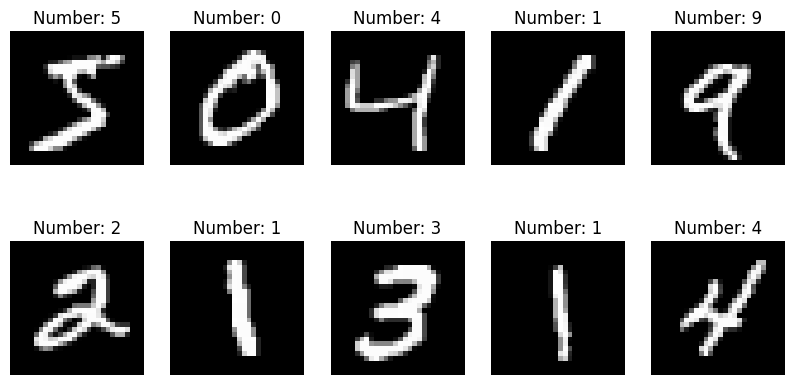

In [13]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Number: {y_train[i]}")
    plt.axis('off')

plt.show()

In [15]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [14]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train[..., np.newaxis],
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9372 - loss: 0.2074 - val_accuracy: 0.9763 - val_loss: 0.0774
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9811 - loss: 0.0595 - val_accuracy: 0.9847 - val_loss: 0.0508
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9870 - loss: 0.0417 - val_accuracy: 0.9851 - val_loss: 0.0478
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9892 - loss: 0.0325 - val_accuracy: 0.9887 - val_loss: 0.0391
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9917 - loss: 0.0246 - val_accuracy: 0.9857 - val_loss: 0.0472


In [17]:
test_loss, test_accuracy = model.evaluate(
    x_test[..., np.newaxis],
    y_test
)

print("최종 테스트 정확도:",
      test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9872 - loss: 0.0386
최종 테스트 정확도: 98.72000217437744 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step


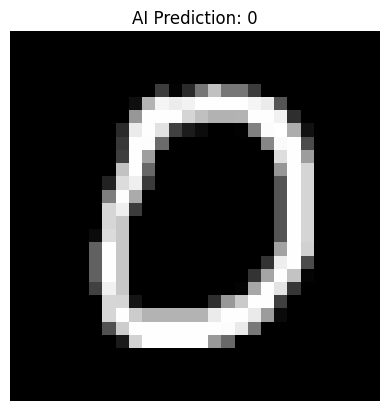

실제 숫자: 0
AI 예측 숫자: 0


In [18]:
index = 10

prediction = model.predict(
    x_test[index].reshape(1, 28, 28, 1)
)

predicted_number = np.argmax(prediction)

plt.imshow(x_test[index], cmap='gray')
plt.title(f"AI Prediction: {predicted_number}")
plt.axis('off')
plt.show()

print("실제 숫자:", y_test[index])
print("AI 예측 숫자:", predicted_number)